## BC3409 BC3415 - Image Classification Workshop

Download Pneumonia Chest X-ray Dataset:

https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia/data

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **CNN**

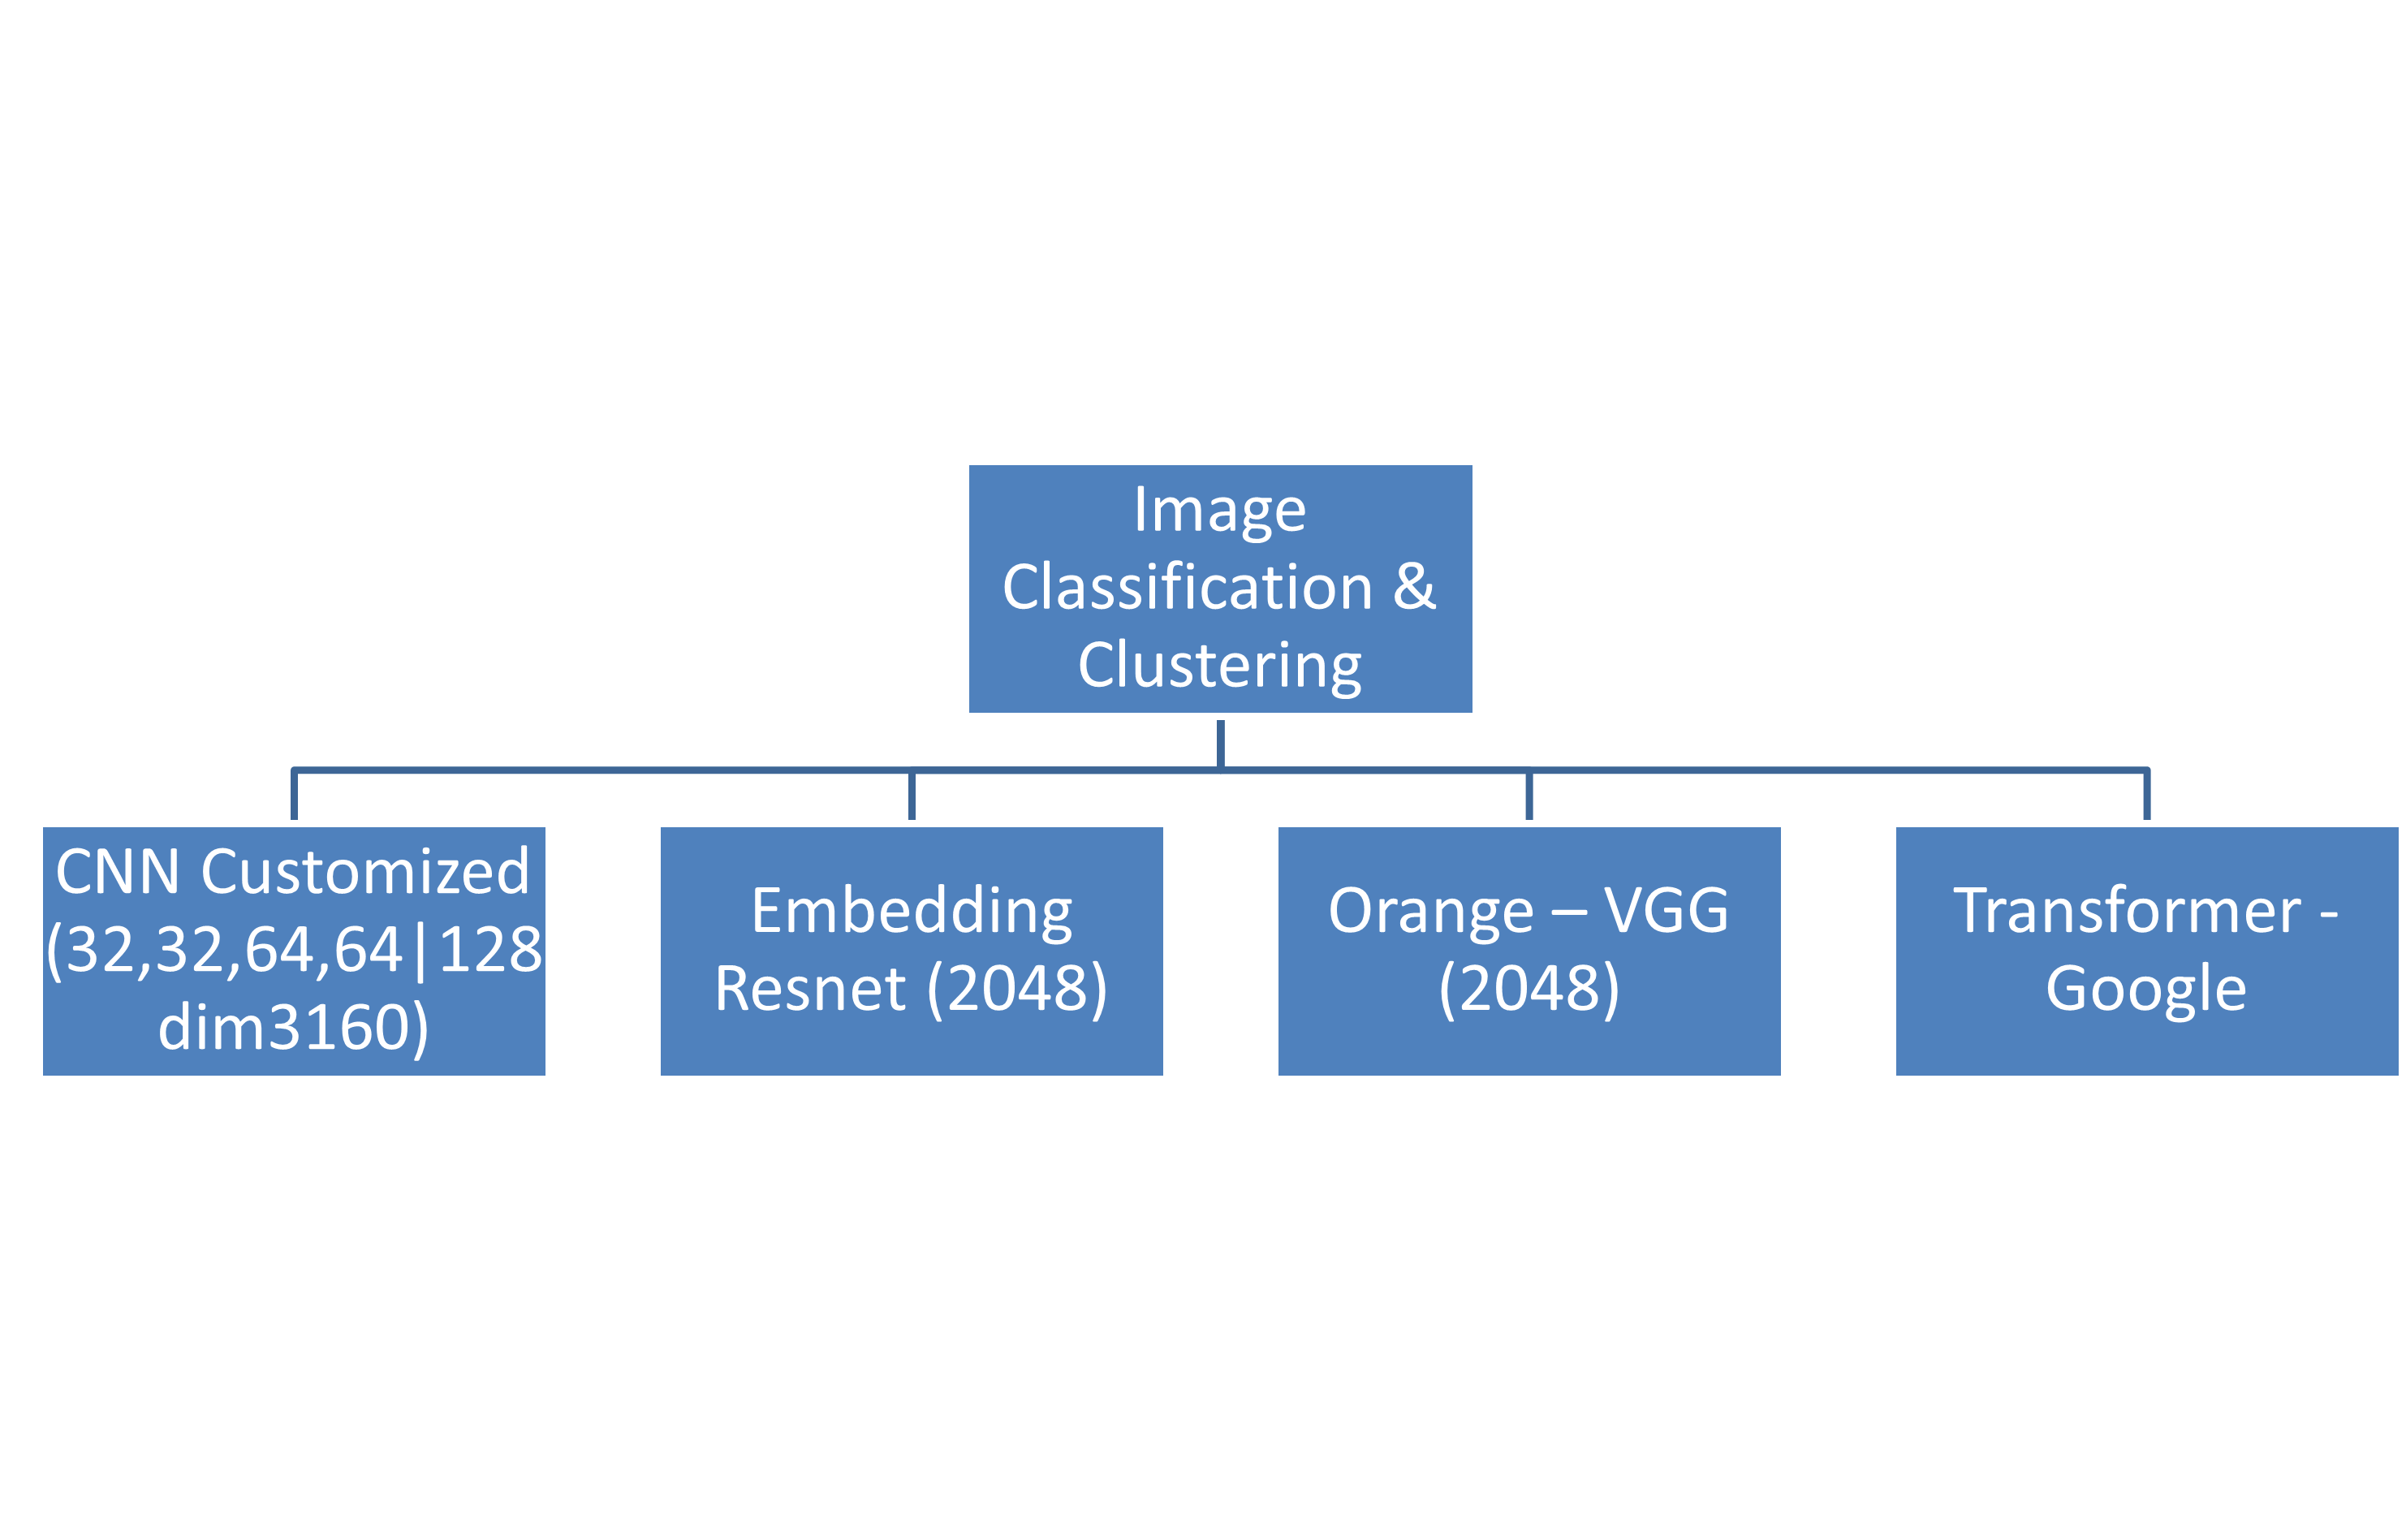

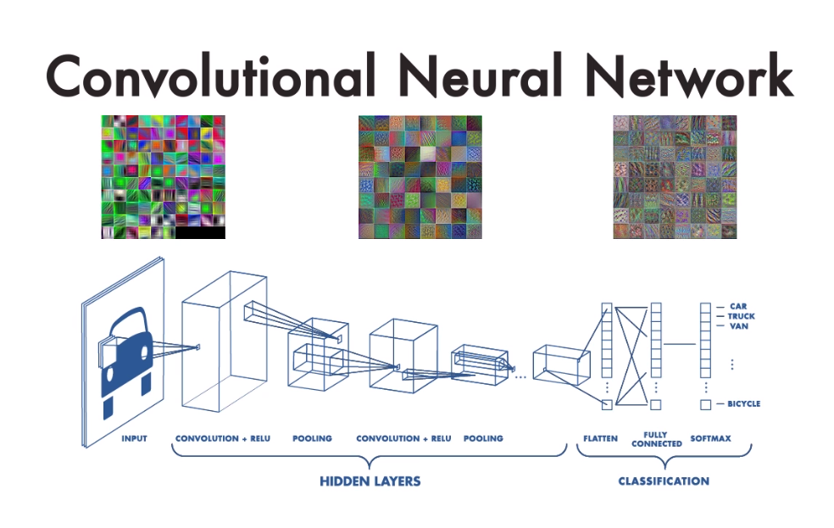

In [19]:
# !pip uninstall tensorflow keras -y

In [20]:
# !pip install tensorflow

In [21]:
# !pip install keras

In [22]:
import tensorflow as tf
print(tf.__version__)

2.17.0


In [34]:
# Set batch size, what is it?
# b = 5
b = 20

---

In [53]:
# 2024-09-04 Sam GU Zhan
# from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import ImageDataGenerator

G = ImageDataGenerator()

# training dataset
train  = "/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train"
# train_data = G.flow_from_directory(train, (150, 150), batch_size=b, shuffle= False)
train_data = G.flow_from_directory(train, (150, 150), batch_size=b, shuffle= True)

Found 5216 images belonging to 2 classes.


In [54]:
# validataion dataset
val  = "/content/drive/MyDrive/AI4AnF/Data/Pneumonia/val"
val_data = G.flow_from_directory(val, (150, 150), batch_size=b, shuffle= False)

Found 16 images belonging to 2 classes.


In [55]:
# test dataset
test = "/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test"
test_data = G.flow_from_directory(test, (150, 150), batch_size=b, shuffle= False)

Found 624 images belonging to 2 classes.


In [60]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D

model = Sequential()

model.add(Conv2D(32, (3, 3), input_shape=(150, 150, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
model.add(Dropout(0.05))

model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
model.add(Dropout(0.05))

model.add(Conv2D(16, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
model.add(Dropout(0.05))

# model.add(Conv2D(64, (3, 3), activation='relu'))
# model.add(MaxPooling2D(pool_size=(2, 2), strides=2))
# model.add(Dropout(0.2))

model.add(Flatten())

# model.add(Dense(128, activation='relu'))
model.add(Dense(16, activation='relu'))

model.add(Dense(2, activation="softmax")) #depends on class
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_39 (Conv2D)                   │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_39 (MaxPooling2D)      │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_37 (Dropout)                 │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_40 (Conv2D)                   │ (None, 72, 72, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_40 (MaxPooling2D)      │ (None, 36, 36, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_38 (Dropout)                 │ (None, 36, 36, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_41 (Conv2D)                   │ (None, 34, 34, 16)          │           4,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_41 (MaxPooling2D)      │ (None, 17, 17, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_39 (Dropout)                 │ (None, 17, 17, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_12 (Flatten)                 │ (None, 4624)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_27 (Dense)                     │ (None, 16)                  │          74,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_28 (Dense)                     │ (None, 2)                   │              34 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 88,802 (346.88 KB)

 Trainable params: 88,802 (346.88 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
#remove optimizer if needed
model.compile(loss="categorical_crossentropy",optimizer="adam",metrics=['accuracy'])

In [62]:
h = model.fit(train_data,
              batch_size = b,
              epochs = 30,
              validation_data=val_data,
              # workers=4,  # Set number of worker threads for data loading
              # use_multiprocessing=True,  # Enable multiprocessing for data loading
              # max_queue_size=10  # Maximum size of the generator queue
              )

Epoch 1/30


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


261/261 ━━━━━━━━━━━━━━━━━━━━ 75s 264ms/step - accuracy: 0.7610 - loss: 3.2139 - val_accuracy: 0.7500 - val_loss: 0.5612
Epoch 2/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 71s 236ms/step - accuracy: 0.9428 - loss: 0.1550 - val_accuracy: 0.9375 - val_loss: 0.2259
Epoch 3/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 84s 245ms/step - accuracy: 0.9621 - loss: 0.1024 - val_accuracy: 0.8750 - val_loss: 0.2146
Epoch 4/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 65s 239ms/step - accuracy: 0.9713 - loss: 0.0940 - val_accuracy: 0.9375 - val_loss: 0.0834
Epoch 5/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 80s 232ms/step - accuracy: 0.9665 - loss: 0.0870 - val_accuracy: 1.0000 - val_loss: 0.0686
Epoch 6/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 61s 229ms/step - accuracy: 0.9724 - loss: 0.0822 - val_accuracy: 1.0000 - val_loss: 0.0548
Epoch 7/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 62s 233ms/step - accuracy: 0.9666 - loss: 0.0950 - val_accuracy: 0.6250 - val_loss: 1.0786
Epoch 8/30
261/261 ━━━━━━━━━━━━━━━━━━━━ 62s 233ms/step - accuracy: 0.9744 - loss: 0.0750 - val

In [14]:
# h = model.fit(train_data, batch_size = b, epochs = 10)

Epoch 1/5


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


63/63 ━━━━━━━━━━━━━━━━━━━━ 804s 11s/step - accuracy: 0.5201 - loss: 16.8393
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 47s 617ms/step - accuracy: 0.6608 - loss: 0.7289
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 88s 726ms/step - accuracy: 0.7768 - loss: 0.5206
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 78s 700ms/step - accuracy: 0.7823 - loss: 0.4385
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 82s 724ms/step - accuracy: 0.8114 - loss: 1.1141


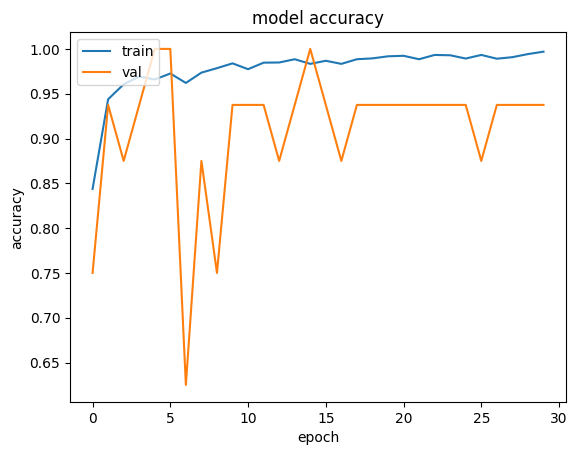

In [63]:
import matplotlib.pyplot as plt
plt.plot(h.history['accuracy'])
plt.plot(h.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()


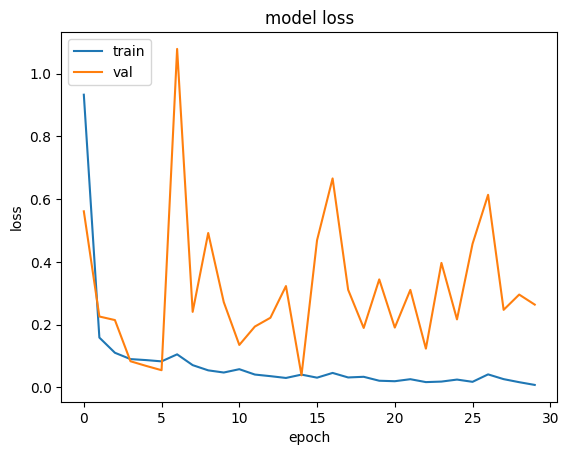

In [64]:
plt.plot(h.history['loss'])
plt.plot(h.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


32/32 ━━━━━━━━━━━━━━━━━━━━ 295s 9s/step


<Axes: >

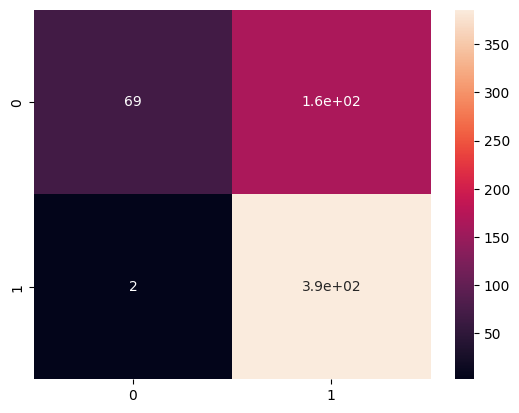

In [51]:
import seaborn as sns
import numpy as np

pred = model.predict(test_data)
pred=np.argmax(pred,axis=1)
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(test_data.classes, pred)
sns.heatmap(cm, annot=True)


In [52]:
print((cm[0,0]+cm[1,1])/(sum(sum(cm))))

0.7315112540192926


In [ ]:
print((cm[0,0]+cm[1,1])/(sum(sum(cm))))

0.7243589743589743


### The End, is the New Start.